# Parkinson's telemonitoring project

This project want to performe a UPDRS score prediction based on Parkinson's patientes' voice recordig parameters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import json
from pathlib import Path
images_dir = Path('images')
images_dir.mkdir(parents = True, exist_ok = True)

In [3]:
from sklearn.model_selection import GroupShuffleSplit, KFold,GroupKFold, cross_validate, cross_val_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# 1. EDA

In [5]:
data = pd.read_csv('data//parkinsons_updrs.data')
print(data.shape,'\n')
print(f'Total subjects in the dataset: {len(data['subject#'].unique())}\n')
print(data.info(),'\n')
#print(data.isna().any().sum()) # quick control about NAN presence
data.head()

(5875, 22) 

Total subjects in the dataset: 42

<class 'pandas.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR            

,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [6]:
total_subjects = len(data['subject#'].unique())
print(f'Subjects in the cohort: {total_subjects}')
data.describe().T

Subjects in the cohort: 42


,count,mean,std,min,25%,50%,75%,max
subject#,5875.0,21.494128,12.372279,1.000000,10.000000,22.000000,33.000000,42.000000
age,5875.0,64.804936,8.821524,36.000000,58.000000,65.000000,72.000000,85.000000
sex,5875.0,0.317787,0.465656,0.000000,0.000000,0.000000,1.000000,1.000000
test_time,5875.0,92.863722,53.445602,-4.262500,46.847500,91.523000,138.445000,215.490000
motor_UPDRS,5875.0,21.296229,8.129282,5.037700,15.000000,20.871000,27.596500,39.511000
total_UPDRS,5875.0,29.018942,10.700283,7.000000,21.371000,27.576000,36.399000,54.992000
Jitter(%),5875.0,0.006154,0.005624,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5875.0,0.000044,0.000036,0.000002,0.000022,0.000035,0.000053,0.000446
Jitter:RAP,5875.0,0.002987,0.003124,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5875.0,0.003277,0.003732,0.000430,0.001820,0.002490,0.003460,0.069560


In [7]:
# TEST_TIME has negstive vlues --> inconsinsetncy?

print(f'Record with negative time: {(data['test_time']<0).sum()} ({len(data[data['test_time']<0])/len(data)*100:.2f}% of data)\n')

neg_time_subjects = data[data['test_time']<0]['subject#'].unique()
print(f'subject with negative test time: {neg_time_subjects} ({len(neg_time_subjects)}/{len(data['subject#'].unique())} subjects)\n')


print(data[data['test_time']<0].groupby(by = 'subject#')['test_time'].value_counts())

data[data['test_time']<0].groupby(by = 'subject#')['test_time'].describe()
# std roughly 0.001 --> multiple examples recording sequentially

Record with negative time: 12 (0.20% of data)

subject with negative test time: [34 42] (2/42 subjects)

subject#  test_time
34        -3.3118      2
          -3.3097      2
          -3.3125      1
          -3.3104      1
42        -4.2625      2
          -4.2597      2
          -4.2618      1
          -4.2604      1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
subject#,,,,,,,,
34,6.0,-3.310983,0.001206,-3.3125,-3.311800,-3.3111,-3.309875,-3.3097
42,6.0,-4.261100,0.001328,-4.2625,-4.262325,-4.2611,-4.259875,-4.2597


**Considerations**: becasuse negative values have a small range and a low std, they could be considered as back-to-back records taken in one sitting. They are edge cases representing a **baseline visit logged before the dataset 'day 0' reference point**

In [8]:
# is dropping those records negligible?
group_neg_time_records = data.groupby('subject#').size().loc[[34, 42]]
num_neg_rec_34= data[(data['subject#']==34) & (data['test_time']<0)].shape[0]
num_neg_rec_42= data[(data['subject#']==42) & (data['test_time']<0)].shape[0]

print(f'Average number of records: {data.groupby('subject#').size().mean():.3f}\n')
print('Subject 34 and 42 total records:')
print(data.groupby('subject#').size().loc[[34, 42]],'\n')

print(f'Subject 34 with negative time data rate: {num_neg_rec_34/group_neg_time_records[34]*100:.2f}%')
print(f'Subject 42 with negative time data rate: {num_neg_rec_42/group_neg_time_records[42]*100:.2f}%')

Average number of records: 139.881

Subject 34 and 42 total records:
subject#
34    161
42    150
dtype: int64 

Subject 34 with negative time data rate: 3.73%
Subject 42 with negative time data rate: 4.00%


In [9]:
# considering the rate of data with negative test_time
# dropping records with 'test_time' < 0 doesn't seem negligible

data = data[data['test_time']>= 0].copy() # data_clean
print(f'Original shape: {data.shape}')
print(f'Data cleaned shape: {data.shape}')

Original shape: (5863, 22)
Data cleaned shape: (5863, 22)


**Target distribution analysis**
 - motor UPDRS value range: 0-108/132 (Mild value <= 32, Moderate <=58, estimated annual increase 2.4)
 - total UPDRS value range: 0-199 ( Mild to Moderate value <= 41, estimated annual increase 4.7 )
 - **total UPDRS = partI + partII + partIII(motor UPDRS)**

In [10]:
# both features could be considered as target

data[['motor_UPDRS','total_UPDRS']].describe().T

,count,mean,std,min,25%,50%,75%,max
motor_UPDRS,5863.0,21.289655,8.133419,5.0377,15.000,20.871,27.5940,39.511
total_UPDRS,5863.0,29.014090,10.709966,7.0000,21.362,27.522,36.4005,54.992


In [11]:
# any motor_UPDRS > total_UPDRS
data[(data['motor_UPDRS'] > data['total_UPDRS'])].any().sum()

np.int64(0)

In [12]:
# mean vs median --> data skewness?

total_mean, total_median = data['total_UPDRS'].mean(), data['total_UPDRS'].median()
motor_mean, motor_median = data['motor_UPDRS'].mean(), data['motor_UPDRS'].median()
skewness = data[['motor_UPDRS','total_UPDRS']].skew()

print(f'Total UPDRS mean: {total_mean:.2f}\ntotal UPDRS median: {total_median:.2f}')
print(f'motor UPDRS mean: {motor_mean:.2f}\nmotor UPDRS median: {motor_median:.2f}')
print(f'\nskew values: \n{skewness}')

# comparing values, scores don't seem to show any skewness

Total UPDRS mean: 29.01
total UPDRS median: 27.52
motor UPDRS mean: 21.29
motor UPDRS median: 20.87

skew values: 
motor_UPDRS    0.076748
total_UPDRS    0.272120
dtype: float64


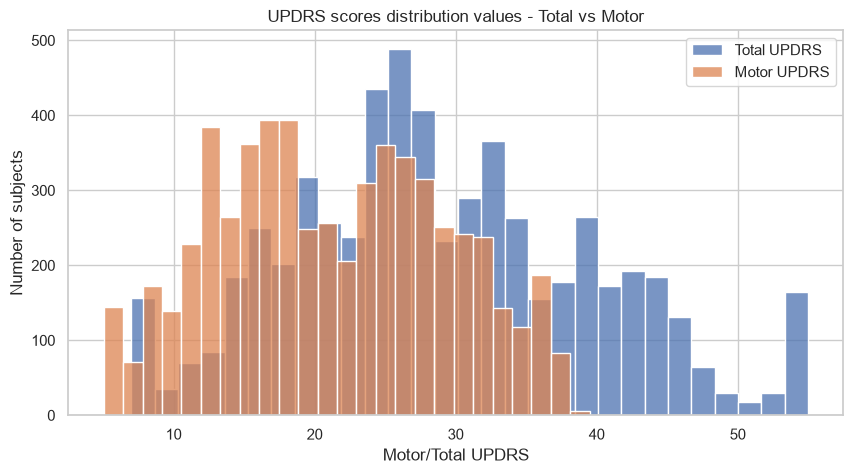

In [13]:
# vlues distribution
plt.figure(figsize = (10,5))
sns.set_theme(style = 'whitegrid')
sns.histplot(data = data, x = 'total_UPDRS', label = 'Total UPDRS')
sns.histplot(data = data, x = 'motor_UPDRS', label = 'Motor UPDRS')
plt.legend()
plt.xlabel('Motor/Total UPDRS')
plt.ylabel('Number of subjects')
plt.title('UPDRS scores distribution values - Total vs Motor')
plt.savefig(images_dir / 'UPDRS_scores_distribution_values_Total_vs_Motor.png', dpi = 300, bbox_inches = 'tight')

# No heavy tail distribution
# it seems to be 2 humps in eache distribution
# total_updrs has 2 contained spikes (end and beginning)
# motor_updrs has 1 contained spike at the beginning
# The two distribution are quite similar, it seems as toal_updrs is a shifted version of motor_updrs --> due to their relationship

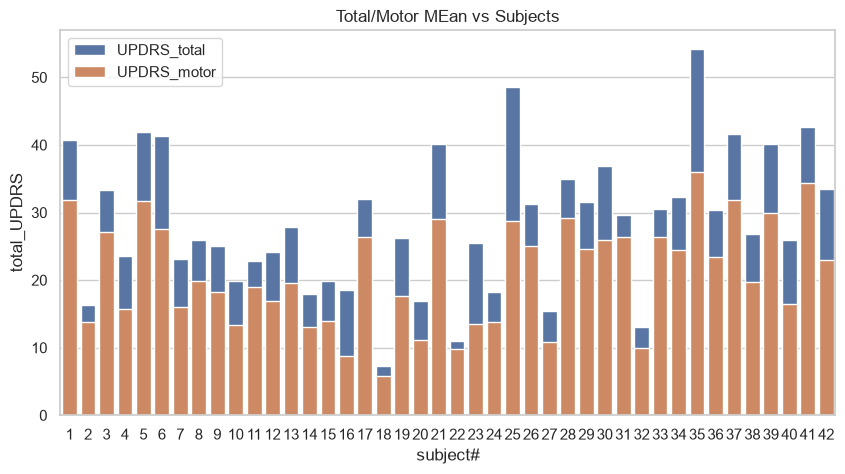

In [14]:
score_per_subj = data.groupby('subject#')[['motor_UPDRS','total_UPDRS']].mean()

sns.set_theme(style = 'whitegrid')
plt.figure(figsize = (10,5))
sns.barplot(data = score_per_subj, x=score_per_subj.index ,y='total_UPDRS', label = 'UPDRS_total')
sns.barplot(data = score_per_subj, x=score_per_subj.index ,y='motor_UPDRS', label = 'UPDRS_motor')
plt.title('Total/Motor MEan vs Subjects')
plt.savefig(images_dir / 'Total_Motor_mean_vs_Subjects.png', dpi = 300, bbox_inches = 'tight')

# this plot confirms a between-patiens variability (range ~7 to ~54), it's not purely a repeated-measures artifact

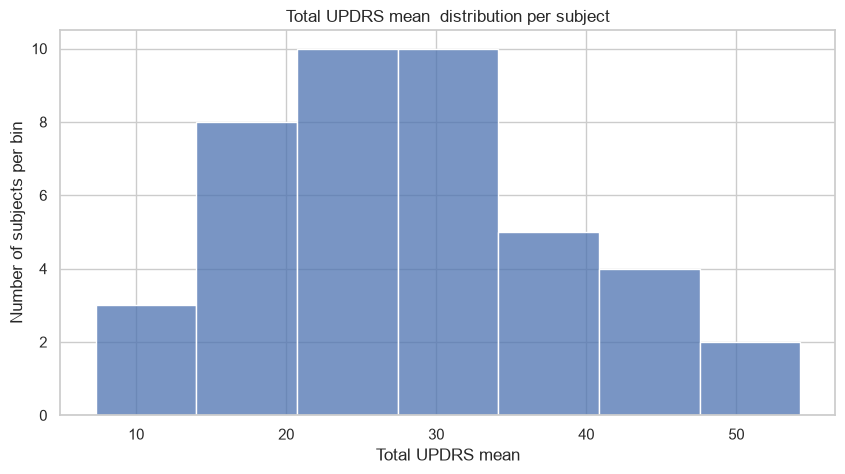

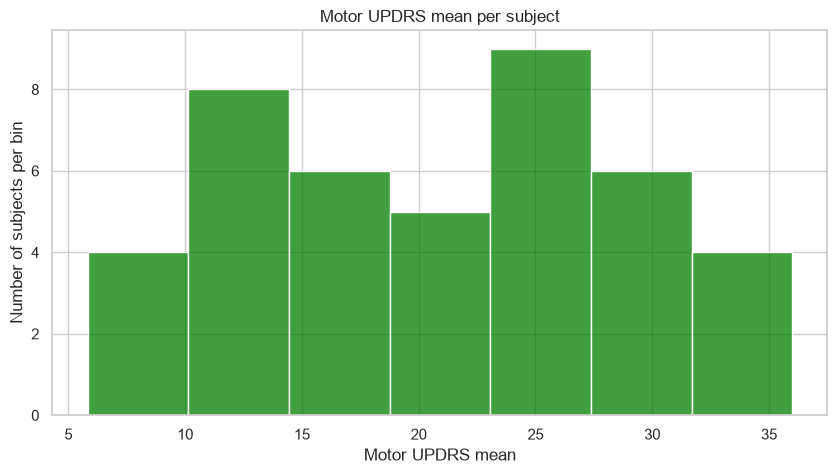

In [15]:
plt.figure(figsize = (10,5))
sns.set_theme(style = 'whitegrid')
sns.histplot(data = score_per_subj , x = 'total_UPDRS')
plt.xlabel('Total UPDRS mean')
plt.ylabel('Number of subjects per bin')
plt.title('Total UPDRS mean  distribution per subject')
plt.savefig(images_dir / 'Total_UPDRS_mean_distribution_per_subject.png', dpi = 300, bbox_inches = 'tight')
plt.show()

plt.figure(figsize = (10,5))
sns.set_theme(style = 'whitegrid')
sns.histplot(data = score_per_subj , x = 'motor_UPDRS', color = 'green')
plt.xlabel('Motor UPDRS mean')
plt.ylabel('Number of subjects per bin')
plt.title('Motor UPDRS mean per subject')
plt.savefig(images_dir / 'Motor_UPDRS_mean_per_subject.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# only motor UPDRS still has a two humps (binomial-looking structure), total UPDRS seems monomodal, but
# with only 42 subjects, I can't confidently confirm or rule out true bimodality from this plot alone.
# For sure, the distribution is not skewed

             motor_UPDRS  total_UPDRS
motor_UPDRS     1.000000     0.947341
total_UPDRS     0.947341     1.000000


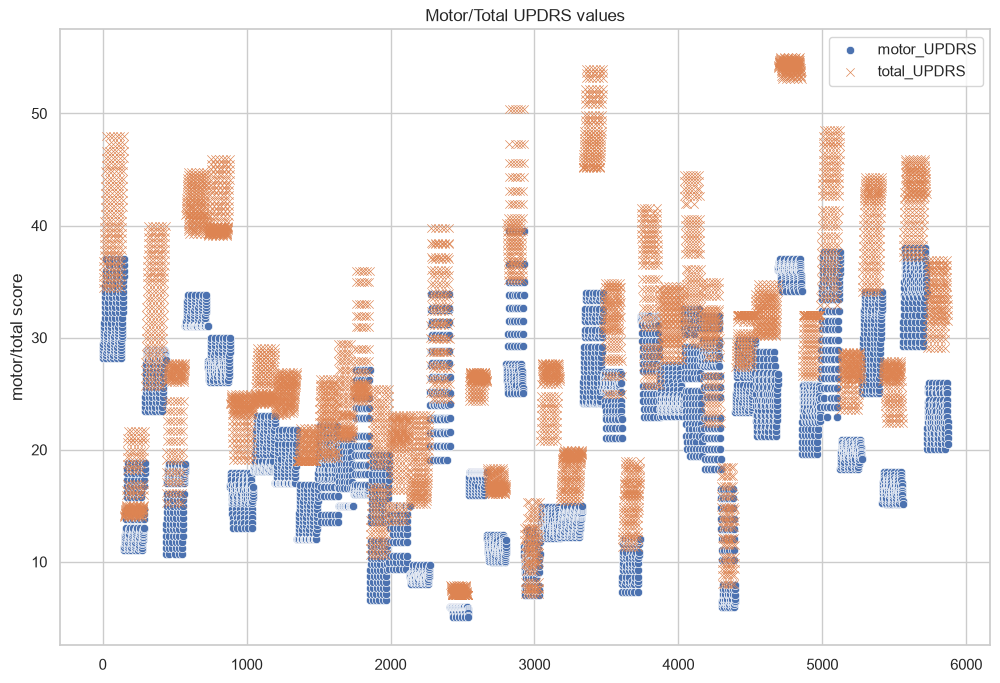

In [16]:
# Motor-Total UPDRS relationship

plt.figure(figsize=(12,8))
sns.scatterplot(data = data, x = data.index, y = 'motor_UPDRS', marker = 'o', label = 'motor_UPDRS')
sns.scatterplot(data = data, x = data.index, y = 'total_UPDRS', marker = 'x', label = 'total_UPDRS')
plt.xlabel('')
plt.ylabel('motor/total score')
plt.title('Motor/Total UPDRS values')
plt.legend()
plt.savefig(images_dir / 'Motor_Total_UPDRS_scatter.png', dpi = 300, bbox_inches = 'tight')

print(data[['motor_UPDRS', 'total_UPDRS']].corr())


# ther is a clear releletion between two scores (total = partI + partII + motor_UPDRS)
# moreover, the correlation underlines the relation beetwen the two targes ( more than 90%)
# this influeces direclty data leakage prblem --> I go on condidering total_UPDRS as target and dropping motor_UPDRS

**Voice recorder parameters analsysis**

The 16 voice measures break into a few families:

- Jitter (frequency instability): Jitter(%), Jitter(Abs), Jitter:RAP, Jitter:PPQ5, Jitter:DDP
- Shimmer (amplitude instability): Shimmer, Shimmer(dB), Shimmer:APQ3, Shimmer:APQ5, Shimmer:APQ11, Shimmer:DDA
- Noise ratios: NHR, HNR
- Nonlinear/complexity measures: RPDE, DFA, PPE

In [17]:
data.columns.values

<StringArray>
[     'subject#',           'age',           'sex',     'test_time',
   'motor_UPDRS',   'total_UPDRS',     'Jitter(%)',   'Jitter(Abs)',
    'Jitter:RAP',   'Jitter:PPQ5',    'Jitter:DDP',       'Shimmer',
   'Shimmer(dB)',  'Shimmer:APQ3',  'Shimmer:APQ5', 'Shimmer:APQ11',
   'Shimmer:DDA',           'NHR',           'HNR',          'RPDE',
           'DFA',           'PPE']
Length: 22, dtype: str

In [18]:
# Summary and shape
voice_col = ['Jitter(%)', 'Jitter(Abs)','Jitter:RAP','Jitter:PPQ5','Jitter:DDP','Shimmer','Shimmer(dB)','Shimmer:APQ3',
             'Shimmer:APQ5','Shimmer:APQ11','Shimmer:DDA','NHR','HNR','RPDE','DFA','PPE']

data[voice_col].describe().T

# considerign that:
# jitter common values < 1% (0.4-0.6% in healthy subjcets)
# shimmer common vaues <3-5%
# there aren't unconcistent values

,count,mean,std,min,25%,50%,75%,max
Jitter(%),5863.0,0.006156,0.005628,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5863.0,0.000044,0.000036,0.000002,0.000022,0.000035,0.000053,0.000446
Jitter:RAP,5863.0,0.002988,0.003126,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5863.0,0.003278,0.003734,0.000430,0.001825,0.002490,0.003470,0.069560
Jitter:DDP,5863.0,0.008965,0.009378,0.000980,0.004730,0.006750,0.009880,0.172630
Shimmer,5863.0,0.034038,0.025836,0.003060,0.019110,0.027530,0.039775,0.268630
Shimmer(dB),5863.0,0.311012,0.230310,0.026000,0.175000,0.253000,0.365000,2.107000
Shimmer:APQ3,5863.0,0.017157,0.013237,0.001610,0.009280,0.013700,0.020605,0.162670
Shimmer:APQ5,5863.0,0.020149,0.016672,0.001940,0.010790,0.015940,0.023775,0.167020
Shimmer:APQ11,5863.0,0.027489,0.020002,0.002490,0.015660,0.022710,0.032725,0.275460


In [19]:
# Considering Jitter %, mean (0.005) << max (0.099) --> artifact or represention of Parkinson's severe condition ?
data[data['Jitter(%)'] > 0.05][['subject#','Jitter(%)','motor_UPDRS','total_UPDRS']]

,subject#,Jitter(%),motor_UPDRS,total_UPDRS
1087,8,0.07183,19.9470,25.947
1880,14,0.09962,7.6466,11.882
4043,30,0.08589,30.2840,41.896
4063,30,0.08929,30.2840,41.896
4106,30,0.09999,30.2830,41.895
4857,36,0.08034,19.6560,26.562
4873,36,0.06031,24.4120,32.000
4877,36,0.05893,23.1770,32.000
4880,36,0.05382,20.1250,26.964
4882,36,0.06714,21.3040,27.975


In [20]:
data[data['subject#'] == 14][['subject#','Jitter(%)','motor_UPDRS','total_UPDRS']].describe().T

,count,mean,std,min,25%,50%,75%,max
subject#,136.0,14.000000,0.000000,14.0000,14.00000,14.000000,14.000000,14.00000
Jitter(%),136.0,0.003644,0.008345,0.0012,0.00236,0.002725,0.003475,0.09962
motor_UPDRS,136.0,13.014450,4.059433,6.5651,9.25960,13.568000,16.801000,19.49100
total_UPDRS,136.0,18.016574,4.639386,10.6460,13.72500,18.649000,22.344000,25.41900


In [21]:
skewness_voice_col = data[voice_col].skew()
mean_voice_col = data[voice_col].mean()
median_voice_col = data[voice_col].median()

voice_feat_data = pd.DataFrame([mean_voice_col,median_voice_col,skewness_voice_col])
voice_feat_data = voice_feat_data.rename(index = {0:'Mean', 1:'Median', 2:'Skewness'})
print(voice_feat_data)
# all voice parameters seem to have a quite >> 0

          Jitter(%)  Jitter(Abs)  Jitter:RAP  Jitter:PPQ5  Jitter:DDP  \
Mean       0.006156     0.000044    0.002988     0.003278    0.008965   
Median     0.004900     0.000035    0.002250     0.002490    0.006750   
Skewness   6.450972     3.283195    6.943769     7.582627    6.943706   

           Shimmer  Shimmer(dB)  Shimmer:APQ3  Shimmer:APQ5  Shimmer:APQ11  \
Mean      0.034038     0.311012      0.017157      0.020149       0.027489   
Median    0.027530     0.253000      0.013700      0.015940       0.022710   
Skewness  3.314150     3.099874      3.098401      3.698075       3.404656   

          Shimmer:DDA       NHR        HNR      RPDE       DFA       PPE  
Mean         0.051470  0.032126  21.679527  0.541423  0.653252  0.219618  
Median       0.041110  0.018448  21.917000  0.542250  0.643550  0.205560  
Skewness     3.098403  6.547359  -0.810924 -0.037453  0.281782  1.088670  


<Figure size 640x480 with 0 Axes>

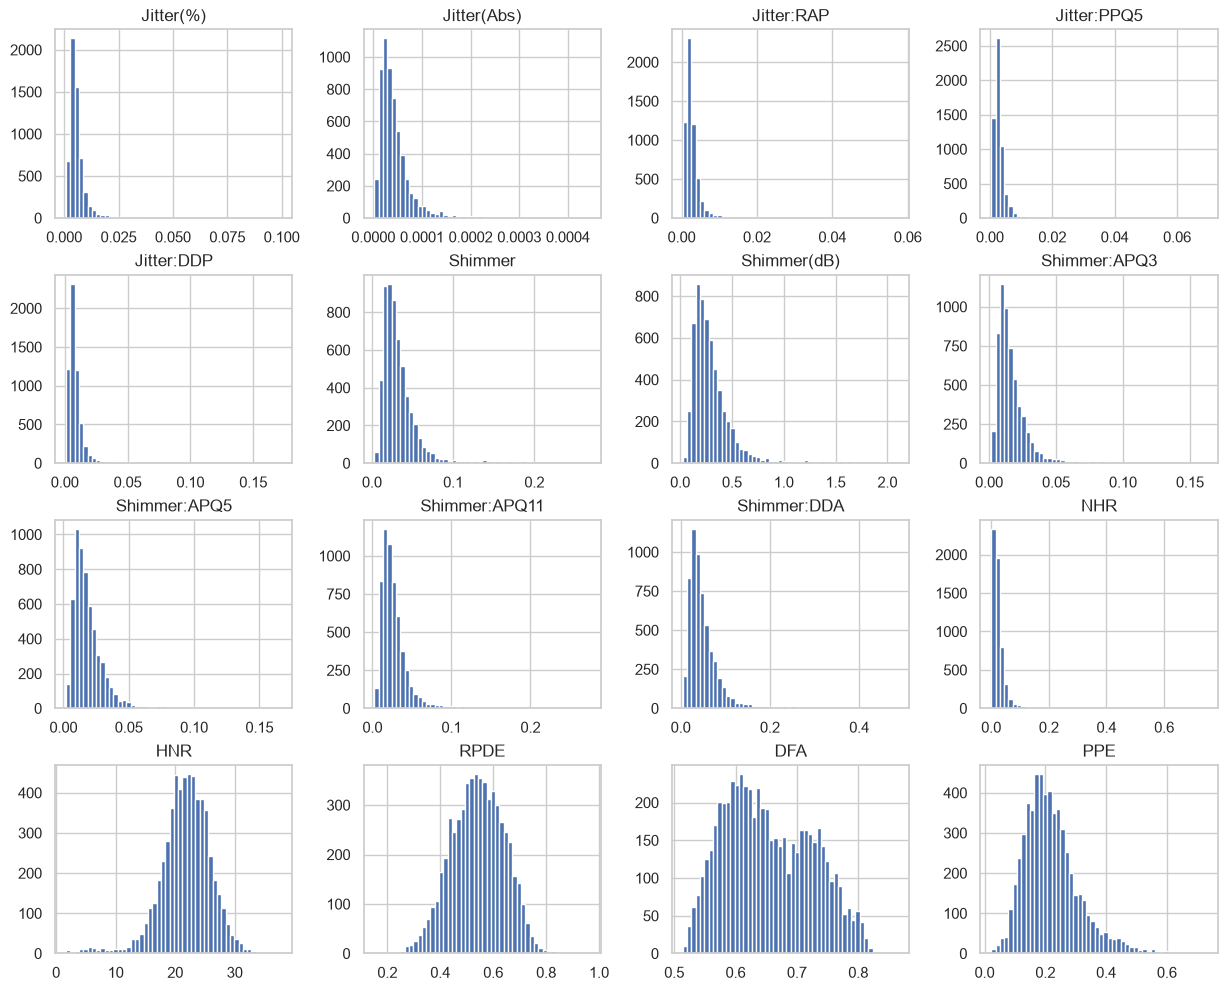

In [22]:
plt.figure()
data[voice_col].hist(bins = 50, figsize= (15,12))
plt.savefig(images_dir / 'voice_columns_hist.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# Jitter and Shimmer parameters have a long-tail distribution (data skewness) --> consider log transformation wether LinearRegression will be used
# non linear/complex reletion parameter seem to have a regular/normal ditribution

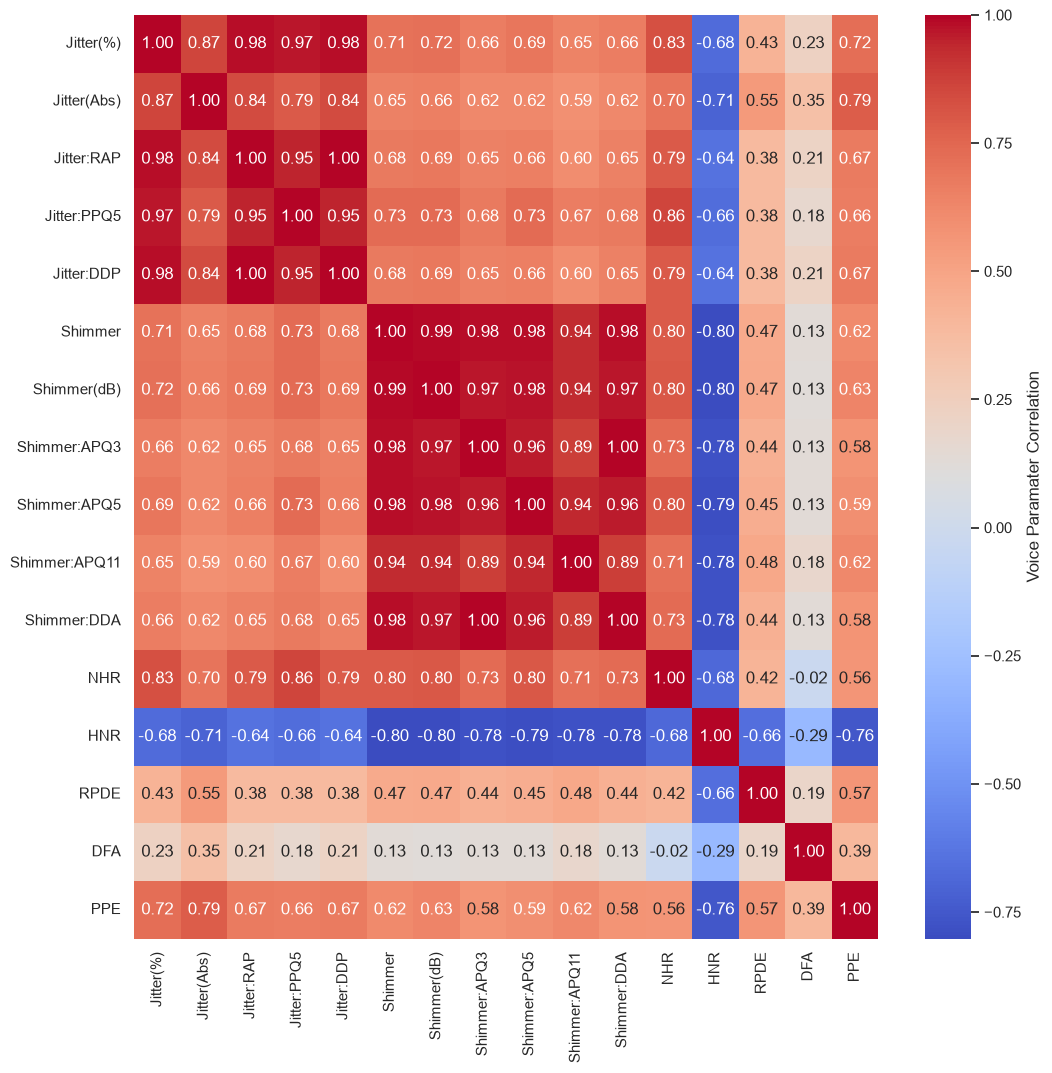

In [23]:
# Correlation among voice feature
voice_col_corr = data[voice_col].corr()

# heatmap
plt.figure(figsize= (12,12))
sns.heatmap(voice_col_corr, annot = True, cmap = 'coolwarm', fmt = '.2f', cbar_kws = {'label': 'Voice Paramater Correlation'})
plt.savefig(images_dir / 'voice_parameter_heatmap.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# high correlation among Jitter and Shimmer parameters and among themselves (extracted from the same type of signal) 
# --> multicollinearity problem wether LineraRegression is used
# RPDE and PPE show a  slight to high correlation, the other way around DFA has lower correlation values

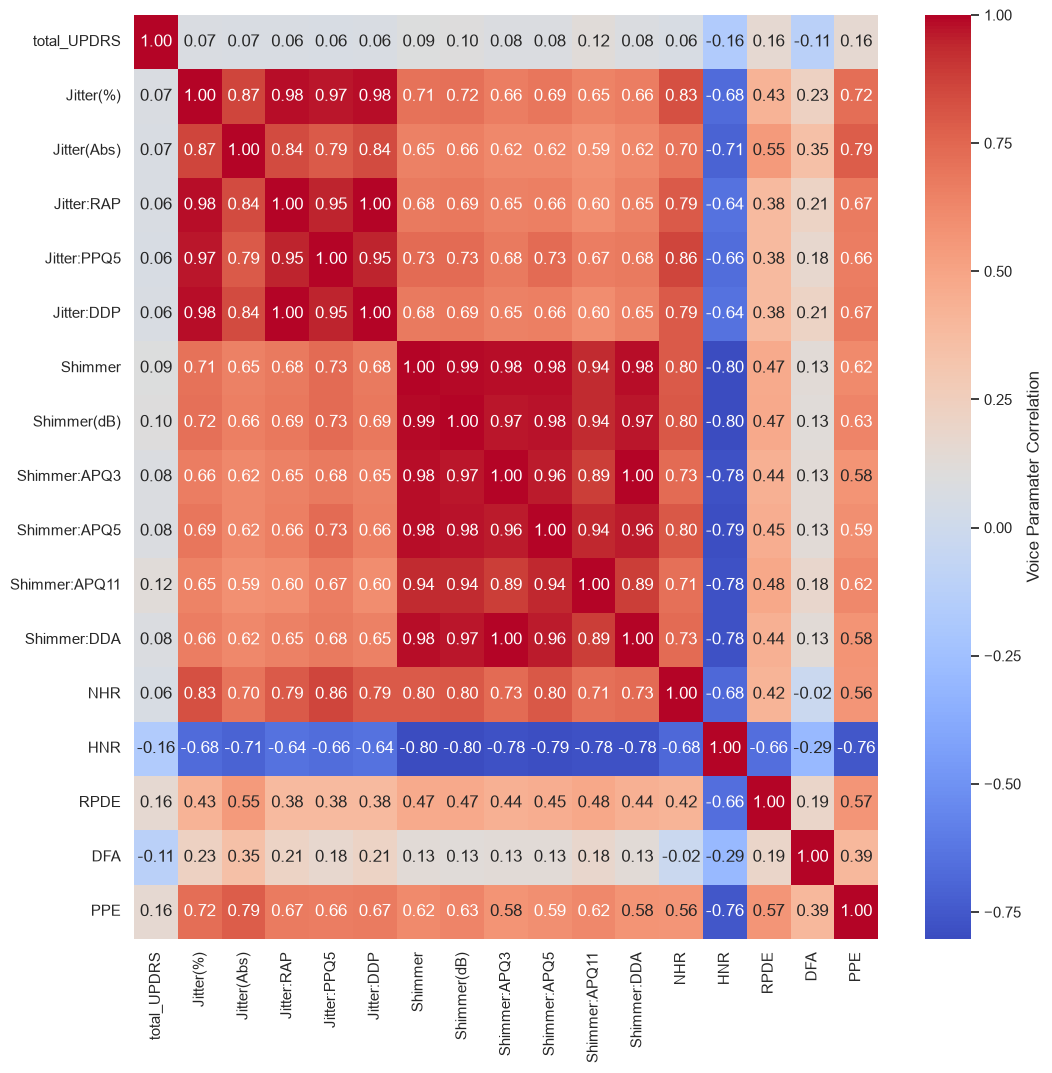

In [24]:
# Voice features vs target (Totl UPDRS)
voice_target_corr = data[(['total_UPDRS'] + voice_col)].corr()
# heatmap
plt.figure(figsize= (12,12))
sns.heatmap(voice_target_corr, annot = True, cmap = 'coolwarm', fmt = '.2f', cbar_kws = {'label': 'Voice Paramater Correlation'})
plt.savefig(images_dir / 'voice_target_heatmap.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# no linear correlation between voice parameters and target

**Demographic features Analysis**

There are 2 demographic features:
- age
- sex

These two parameter does't change their value by records, but by patiens. So, patient-level analys must be done.

In [25]:
dem_col = ['age','sex']

print(data.groupby('subject#')[dem_col].nunique().max() == 1) # using .first() is safe?

subject_info = data.groupby('subject#')[dem_col].first()
subject_info.head()

age    True
sex    True
dtype: bool


,age,sex
subject#,,
1,72,0
2,58,0
3,57,0
4,74,0
5,75,0


In [26]:
# age summary
subject_info['age'].describe()

count    42.000000
mean     64.404762
std       9.239521
min      36.000000
25%      58.000000
50%      65.000000
75%      72.000000
max      85.000000
Name: age, dtype: float64

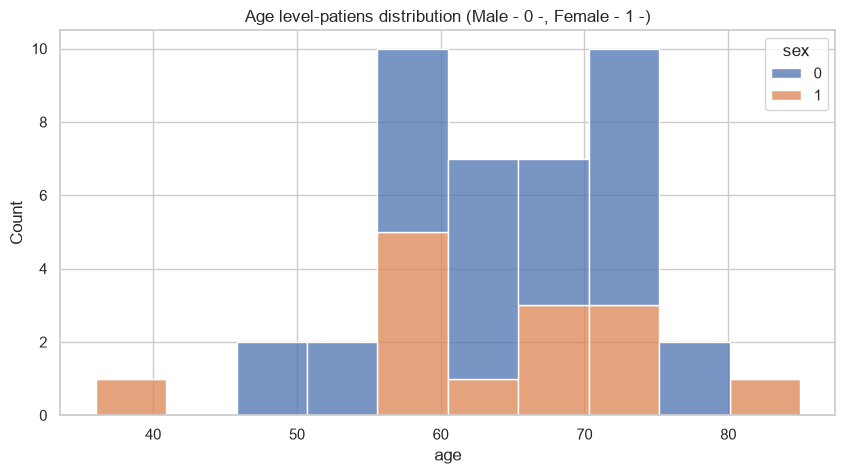

In [27]:
plt.figure(figsize = (10,5))
sns.histplot(data = subject_info, x = 'age', hue = 'sex', bins = 10, multiple = 'stack')
plt.title('Age level-patiens distribution (Male - 0 -, Female - 1 -)')
plt.savefig(images_dir / 'Age_level_patiens_distribution.png', dpi = 300, bbox_inches = 'tight')

In [28]:
# sex distribution
subject_info['sex'].value_counts()

sex
0    28
1    14
Name: count, dtype: int64

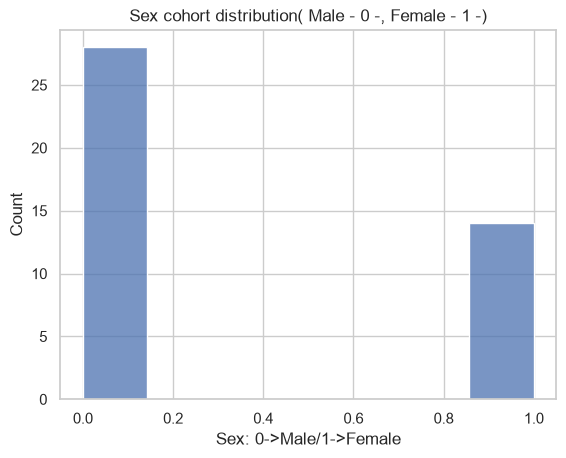

In [29]:
ax = sns.histplot(data = subject_info, x = 'sex')
plt.xlabel('Sex: 0->Male/1->Female')
plt.title('Sex cohort distribution( Male - 0 -, Female - 1 -)')
plt.savefig(images_dir / 'Sex_cohort_distribution.png', dpi = 300, bbox_inches = 'tight')

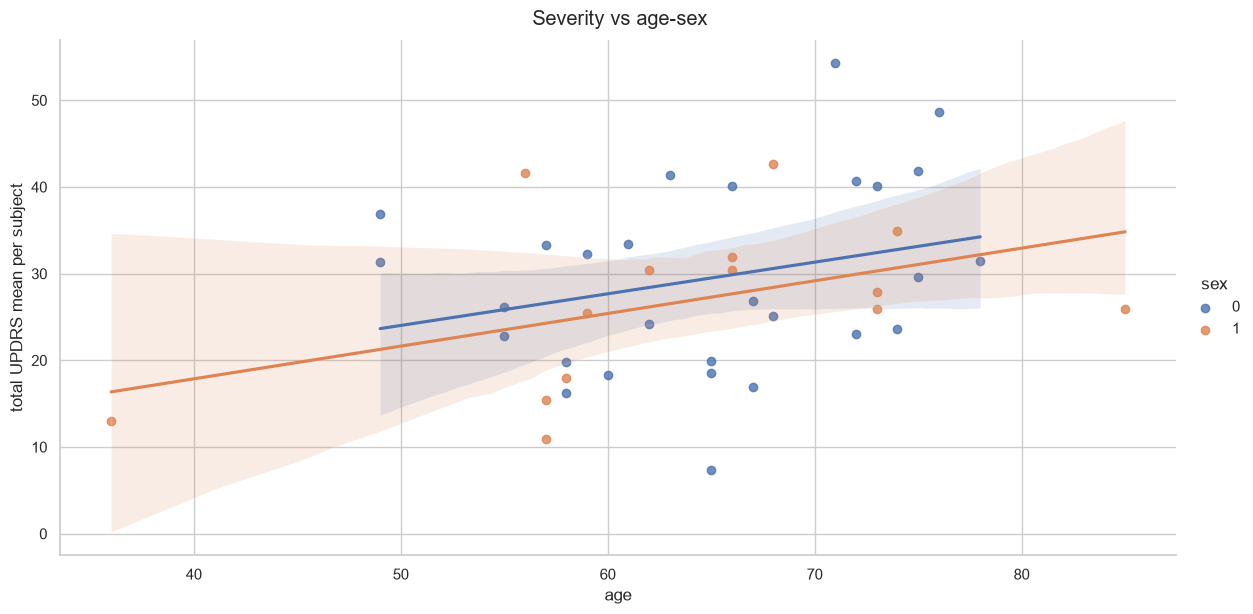

In [30]:
# Relationship to severity (totl_UPDRS)
combined_info = pd.concat([subject_info,score_per_subj.drop(columns = ['motor_UPDRS'])], axis = 1)
# score_per_subj --> motor and total UPDRS mean per subject
g = sns.lmplot(data = combined_info, x = 'age', y = 'total_UPDRS', hue = 'sex', height = 6, aspect = 2)
g.figure.suptitle('Severity vs age-sex', y = 1.02)
g.set_ylabels('total UPDRS mean per subject')
g.savefig(images_dir / 'Severity_vs_age_sex.png', dpi = 300, bbox_inches = 'tight')

# it seems to be a trend: total UPDRS increases as age do
# thoug, let's see ta correlation

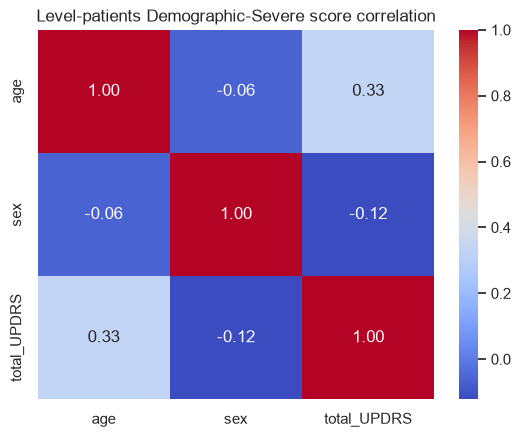

In [31]:
# Correlation 
combined_info_corr = combined_info.corr()

sns.heatmap(combined_info_corr, annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.title('Level-patients Demographic-Severe score correlation')
plt.savefig(images_dir /'Level_patients_Demographic_Severe_score_correlation.png', dpi = 300, bbox_inches = 'tight')

# there is a slight correlation between age and diseas severity

In [32]:
# sex vs severity
combined_info.groupby('sex').agg(total_UPDRS_mean = ('total_UPDRS','mean'), total_UPDRS_std = ('total_UPDRS','std'), total_UPDRS_count = ('total_UPDRS','count'))

,total_UPDRS_mean,total_UPDRS_std,total_UPDRS_count
sex,,,
0,29.435280,10.831091,28
1,26.751368,9.760141,14


# 2. Feature Engineering - Preprocess pipeline

#### Splitting data

In [33]:
# split data: the dataset contains 5.863 records, but there are only 42 unique subjects
# a plain data split causes the presence of same subjects in each train and test data --> data leakege at patiens level
# Different split strategy taking in account groups of subjects --> Group Based Split

# data and target split
X = data.drop(columns = ['motor_UPDRS', 'total_UPDRS']).copy()
y = data['total_UPDRS']

# group selection for train/test split
group = X['subject#']

# splitter object
gss = GroupShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)

# retrive train/test indices
train_idx, test_idx = next(gss.split(X, y, groups = group))

# split train/test data
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f'Test size shape expected (20% of data): {len(X)*0.2:.2f}, actual Test size: {len(X_test)}')
# As expected, since subjects don't have the same recording number, gss can't performe a perfect split of X, the X_test length approximates the desired split
print(f'Train shape: {X_train.shape}, Test shape: {X_test.shape}')
print(f'Train subjects: {X_train["subject#"].nunique()}, Test subjects: {X_test["subject#"].nunique()}')
print(f'Overlap check (should be empty set): {set(X_train["subject#"]) & set(X_test["subject#"])}')

Test size shape expected (20% of data): 1172.60, actual Test size: 1235
Train shape: (4628, 20), Test shape: (1235, 20)
Train subjects: 33, Test subjects: 9
Overlap check (should be empty set): set()


In [34]:
# Is the split balanced?

# demographic analysis
print(X_train.groupby('subject#')['sex'].first().value_counts())
print(X_test.groupby('subject#')['sex'].first().value_counts())
# equal sex distribution in train and test (ratio 2:1)

sex
0    22
1    11
Name: count, dtype: int64
sex
0    6
1    3
Name: count, dtype: int64


In [35]:
# voice parameter + age through standardized mean difference (SMD)

smd = ((X_train[voice_col + ['age']].mean() - X_test[voice_col + ['age']].mean())/X_train[voice_col + ['age']].std())

smd.sort_values(ascending = False)

# DFA shows a great difference between train and test set

NHR              0.130701
HNR              0.046344
Shimmer:APQ3     0.022936
Shimmer:DDA      0.022929
Shimmer(dB)      0.013186
Shimmer          0.012488
Shimmer:APQ5     0.005472
Shimmer:APQ11   -0.052646
age             -0.074365
Jitter:PPQ5     -0.082161
Jitter:DDP      -0.110683
Jitter:RAP      -0.110701
Jitter(%)       -0.135932
RPDE            -0.145886
PPE             -0.338912
Jitter(Abs)     -0.356603
DFA             -0.945673
dtype: float64

In [36]:
# target train/test set distribution

print(y_train.describe())
print(y_test.describe())
smd_target = abs((y_train.mean() - y_test.mean())/y_train.std())

print(f'Standard Mean Difference for total_UPDRS across train/test: {smd_target:.2f}')
# statistics descriotion doesn't show a great difference about the diseas severity between train and test set

count    4628.000000
mean       29.560868
std        11.035521
min         7.000000
25%        21.712750
50%        28.068000
75%        37.275000
max        54.992000
Name: total_UPDRS, dtype: float64
count    1235.000000
mean       26.965113
std         9.106518
min        10.646000
25%        18.362000
50%        26.261000
75%        33.072500
max        44.761000
Name: total_UPDRS, dtype: float64
Standard Mean Difference for total_UPDRS across train/test: 0.24


Consideration:
- Sex: 22/11 in train and 6/3 in test. Both are a 2:1 ratio, so the sex balance is fine at the patient level.
- Age: SMD is 0.07, which is negligible.
- Voice features: DFA is the only large shift (0.95). Jitter(Abs) and PPE are moderate (about 0.35), and everything else is small.
- Target: the means differ by about 0.24 SD, a narrow difference but test set has no patients in the top severity band, so it can’t tell us how well the model handles the most severe cases.

Conclusion: 
- Considering that with only 9 subjects a percet balanace split never occurs, I hold this split
- Keeping in mind DFA difference: using this split, the model will be trained on low DFA value, to take in account in relation to Feature Importance

#### Voice parameter Preprocessing
Considering that tree basd model handle collinear features fine but linear regression doesn't, I keep two feature set:
- Raw feature for tree model or similar
- Compressed features for linear model:
    - Jimmer/Shimmer family --> Log transform --> Standardize --> PCA
    - HNR --> Log transform --> Standardize
    - NRH, RPDE, DFA, PPE --> Standardize

In [37]:
# Quick exploratory version
voice_col

['Jitter(%)',
 'Jitter(Abs)',
 'Jitter:RAP',
 'Jitter:PPQ5',
 'Jitter:DDP',
 'Shimmer',
 'Shimmer(dB)',
 'Shimmer:APQ3',
 'Shimmer:APQ5',
 'Shimmer:APQ11',
 'Shimmer:DDA',
 'NHR',
 'HNR',
 'RPDE',
 'DFA',
 'PPE']

In [38]:
# Jitter family analysis
jitter_train = X_train[voice_col[:5]].copy()
jitter_test = X_test[voice_col[:5]].copy()

[94.66  3.91  0.97  0.46  0.  ]
PC0 importance: 94.66%
2 principal component cover the 95% of the whole information
PC1 loadings: [0.455388   0.42465855 0.45221895 0.450866   0.45222203]


Text(0.5, 1.0, 'PCA JITTER parameters')

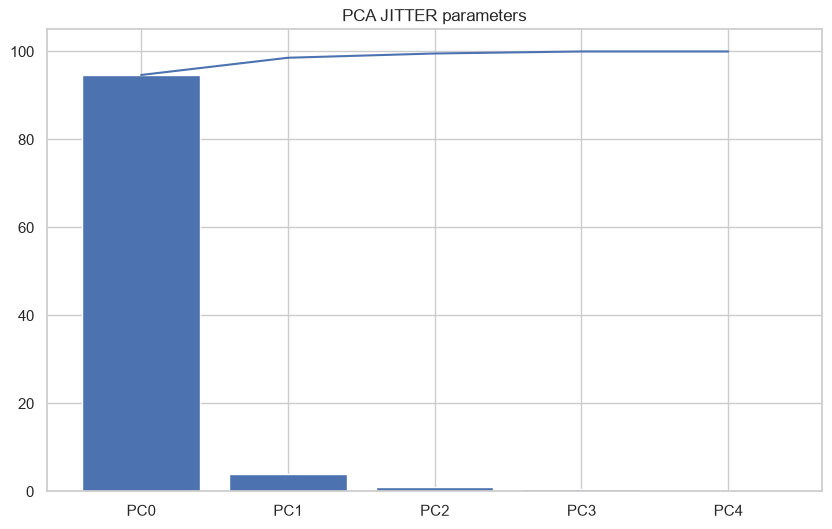

In [39]:
# log transform
jitter_train_ln = np.log(jitter_train)
jitter_test_ln = np.log(jitter_test)

# scaler
jitter_scaler = StandardScaler().fit(jitter_train_ln)
jitter_train_std = jitter_scaler.transform(jitter_train_ln)
jitter_test_std = jitter_scaler.transform(jitter_test_ln)

# PCA

jitter_pca = PCA()
# fit pca
jitter_pca.fit(jitter_train_std)
# transform
pca_jitter_train = jitter_pca.transform(jitter_train_std)
pca_jitter_test = jitter_pca.transform(jitter_test_std)

# variance explanation
ex_var = np.round(jitter_pca.explained_variance_ratio_*100, decimals = 2)

labels_jitter_pca = ['PC' + str(x) for x in range(0,len(ex_var))]
#pca_train_df = pd.DataFrame(pca_train, columns = labels_pca)
#print(pca_train_df.head(3)

print(ex_var)
cum_sum = 0
for i in range(0,len(ex_var)):
    cum_sum += ex_var[i]
    if cum_sum < 95:
        print(f'{labels_jitter_pca[i]} importance: {ex_var[i]}%')
    else:
        print(f'{i+1} principal component cover the 95% of the whole information')
        break

print(f'PC1 loadings: {jitter_pca.components_[0]}')

plt.figure(figsize = (10,6))
plt.plot(np.cumsum(ex_var))
plt.bar(x = range(0,len(ex_var)), height = ex_var, tick_label = labels_jitter_pca)
plt.title('PCA JITTER parameters')

In [40]:
# Shimmer family analysis
shimmer_train = X_train[voice_col[5:11]].copy()
shimmer_test = X_test[voice_col[5:11]].copy()

[9.756e+01 1.700e+00 4.900e-01 1.800e-01 7.000e-02 0.000e+00]
1 principal component cover the 95% of the whole information
PC1 loadings: [0.41245455 0.4088052  0.40871278 0.41113029 0.39954879 0.40871268]


Text(0.5, 1.0, 'PCA SHIMMER parameters')

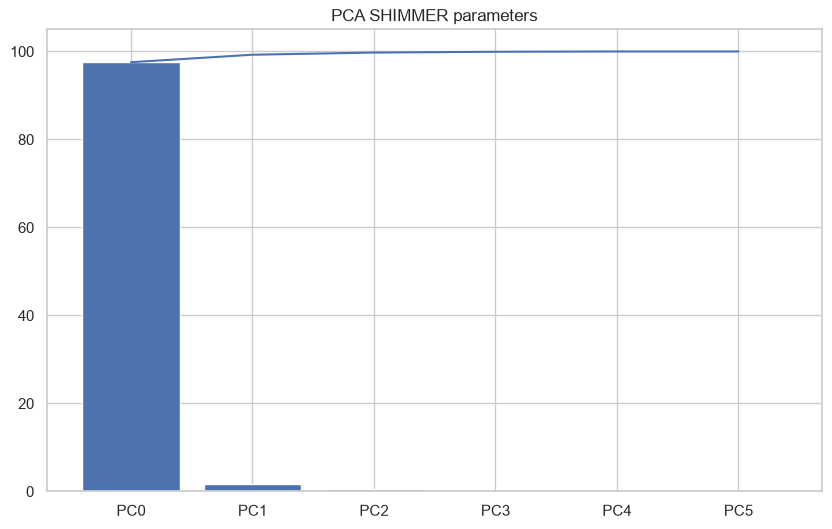

In [41]:
# log transform
shimmer_train_ln = np.log(shimmer_train)
shimmer_test_ln = np.log(shimmer_test)

# scaler
shimmer_scaler = StandardScaler().fit(shimmer_train_ln)
shimmer_train_std = shimmer_scaler.transform(shimmer_train_ln)
shimmer_test_std = shimmer_scaler.transform(shimmer_test_ln)

# PCA

shimmer_pca = PCA()
# fit pca
shimmer_pca.fit(shimmer_train_std)
# transform
pca_shimmer_train =shimmer_pca.transform(shimmer_train_std)
pca_shimmer_test = shimmer_pca.transform(shimmer_test_std)

# variance explanation
ex_var_shimmer = np.round(shimmer_pca.explained_variance_ratio_*100, decimals = 2)

labels_shimmer_pca = ['PC' + str(x) for x in range(0,len(ex_var_shimmer))]
#pca_train_df = pd.DataFrame(pca_train, columns = labels_pca)
#print(pca_train_df.head(3)

print(ex_var_shimmer)
cum_sum = 0
for i in range(0,len(ex_var_shimmer)):
    cum_sum += ex_var_shimmer[i]
    if cum_sum < 95:
        print(f'{labels_shimmer_pca[i]} importance: {ex_var_shimmer[i]}%')
    else:
        print(f'{i+1} principal component cover the 95% of the whole information')
        break

print(f'PC1 loadings: {shimmer_pca.components_[0]}')


plt.figure(figsize = (10,6))
plt.plot(np.cumsum(ex_var_shimmer))
plt.bar(x = range(0,len(ex_var_shimmer)), height = ex_var_shimmer, tick_label = labels_shimmer_pca)
plt.title('PCA SHIMMER parameters')

**Considerations**:

- Jitter --> PC1 captures 94.7% of the variance
- Shimmer --> PC1 captures 97.6% of the variance

Roughly 95 and 98% of the variance means that **information that varie across recordings** is kept. Thoug, it doesn't prove that the 2 to 5% is useless for predictinf UPDRS (use CV comparison against raw feture).

#### Preprocessing Pipeline for Linear Regressor

- Jimmer/Shimmer family --> Log transform --> Standardize --> PCA
- HNR --> Log transform --> Standardize
- NRH, RPDE, DFA, PPE, Age, test_time --> Standardize
- sex --> passthrough

In [42]:
# separate feature name
jitter_col = ['Jitter(%)','Jitter(Abs)','Jitter:RAP','Jitter:PPQ5', 'Jitter:DDP']
shimmer_col = ['Shimmer','Shimmer(dB)','Shimmer:APQ3','Shimmer:APQ5','Shimmer:APQ11','Shimmer:DDA']
scale_only_cols = ['age', 'HNR', 'RPDE', 'DFA', 'PPE'] # 'test_time' ablated (no information provided at patient-level)

In [43]:
jitter_pipeline = Pipeline(steps = [('log', FunctionTransformer(np.log, feature_names_out = 'one-to-one')), 
                                    ('scale', StandardScaler()), 
                                    ('pca', PCA(n_components = 1))])

shimmer_pipeline = Pipeline(steps = [('log', FunctionTransformer(np.log, feature_names_out = 'one-to-one')), 
                                     ('scale', StandardScaler()), 
                                     ('pca', PCA(n_components = 1))])

nhr_pipeline = Pipeline(steps = [('log', FunctionTransformer(np.log, feature_names_out = 'one-to-one')),
                                  ('scale', StandardScaler())])

linear_preprocessor = ColumnTransformer(transformers = [('jitter_prep', jitter_pipeline, jitter_col), 
                                                 ('shimmer_prep', shimmer_pipeline, shimmer_col), 
                                                 ('nhr_prep', nhr_pipeline, ['NHR']), 
                                                 ('scale_only', StandardScaler(), scale_only_cols), 
                                                 ('sex_pass', 'passthrough', ['sex'])], # to not preprocess sex
                                  remainder = 'drop') # to drop subject id


In [44]:
X_train_test = linear_preprocessor.fit_transform(X_train)
linear_preprocessor.get_feature_names_out()

array(['jitter_prep__pca0', 'shimmer_prep__pca0', 'nhr_prep__NHR',
       'scale_only__age', 'scale_only__HNR', 'scale_only__RPDE',
       'scale_only__DFA', 'scale_only__PPE', 'sex_pass__sex'],
      dtype=object)

#### Cross Validation Strategy

In [45]:
#group definition
group_train = X_train['subject#']

# cv strategy
cv = GroupKFold(n_splits = 5)

cv_plain = KFold(n_splits = 5, shuffle = True, random_state = 42)

# metrics
scoring = ['neg_root_mean_squared_error', 'neg_mean_absolute_error', 'r2']

# utility function for evaluation through cross_validate, 
def evaluate(model_name, model, preprocessor):
    model_pipeline = Pipeline([('prep', preprocessor),('model',model)])
    res = cross_validate(model_pipeline, X_train, y_train, groups = group_train, cv = cv, scoring = scoring) 
    # cross_validate output: fit_time, score_time, test_neg_root_mean_squared_error, test_neg_mean_absolute_error, test_r2
    res = pd.DataFrame(res).rename(columns = {'test_neg_root_mean_squared_error': f'{model_name} RMSE', 
                                             'test_neg_mean_absolute_error': f'{model_name} MAE',
                                             'test_r2': f'{model_name} R2'})
    res = res.drop(columns = ['fit_time','score_time'])
     # sklearn returns negated errors: flip the sign back
    res[f'{model_name} RMSE'] = -res[f'{model_name} RMSE']
    res[f'{model_name} MAE'] = -res[f'{model_name} MAE']
    return res

# Plain Cross Validation (raw-level)
def evaluate2(model_name,model, preprocessor):
    model_pipeline = Pipeline([('prep', preprocessor),('model',model)])
    res = cross_validate(model_pipeline, X_train, y_train, cv = cv_plain, scoring = scoring)
   # cross_validate output: fit_time, score_time, test_neg_root_mean_squared_error, test_neg_mean_absolute_error, test_r2
    res = pd.DataFrame(res).rename(columns = {'test_neg_root_mean_squared_error': f'{model_name} RMSE', 
                                             'test_neg_mean_absolute_error': f'{model_name} MAE',
                                             'test_r2': f'{model_name} R2'})
    res = res.drop(columns = ['fit_time','score_time'])
     # sklearn returns negated errors: flip the sign back
    res[f'{model_name} RMSE'] = -res[f'{model_name} RMSE']
    res[f'{model_name} MAE'] = -res[f'{model_name} MAE']
    
    return res

# 3. Model Selection

### 3.1 Linear Model

Dummy Regressor

In [46]:
dummy_model = DummyRegressor(strategy = 'mean')

dummy_res = evaluate('dummy', dummy_model, linear_preprocessor)


dummy_res

,dummy RMSE,dummy MAE,dummy R2
0,7.380411,5.771618,-0.004837
1,11.706682,8.967269,-0.035147
2,14.200536,11.657657,-0.000198
3,9.953761,7.914646,-0.021209
4,10.486874,9.837801,-0.000243


In [47]:
dummy_res.describe().T

,count,mean,std,min,25%,50%,75%,max
dummy RMSE,5.0,10.745653,2.493928,7.380411,9.953761,10.486874,11.706682,14.200536
dummy MAE,5.0,8.829799,2.192129,5.771618,7.914646,8.967269,9.837801,11.657657
dummy R2,5.0,-0.012327,0.015402,-0.035147,-0.021209,-0.004837,-0.000243,-0.000198


Considerations:

- mean RMSE and MSE high values. RMSE mean is near to target std (rougly 11)
- there are large spread across folds, but it's due to fold's validation subject
- due to this reason, a clearer comparison among model can be performed considering RMSE in each fold

In [48]:
# Linear Regressor

linear_model = LinearRegression()

linear_res = evaluate('linear',linear_model,linear_preprocessor)
    

# RIDGE model

ridge_model = Ridge(alpha = 1)

ridge_res = evaluate('ridge', ridge_model,linear_preprocessor)


# comparing model

print(dummy_res)
print(linear_res)
print(ridge_res)

   dummy RMSE  dummy MAE  dummy R2
0    7.380411   5.771618 -0.004837
1   11.706682   8.967269 -0.035147
2   14.200536  11.657657 -0.000198
3    9.953761   7.914646 -0.021209
4   10.486874   9.837801 -0.000243
   linear RMSE  linear MAE  linear R2
0     7.613876    6.003946  -0.069414
1    11.106232    8.920460   0.068318
2    14.021785   11.364668   0.024824
3     9.249777    8.087327   0.118134
4    11.502406    9.247391  -0.203346
   ridge RMSE  ridge MAE  ridge R2
0    7.612876   6.003099 -0.069133
1   11.105463   8.919496  0.068447
2   14.020448  11.364089  0.025010
3    9.249615   8.087231  0.118164
4   11.500721   9.246386 -0.202994


In [49]:
# comparing RMSE difference
score_by_model = dummy_res[['dummy RMSE','dummy R2']].copy()
score_by_model[['linear RMSE','linear R2']] = linear_res[['linear RMSE','linear R2']]
print('Score comparison (5-fold group cross validation)')
print(score_by_model)

Score comparison (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2
0    7.380411 -0.004837     7.613876  -0.069414
1   11.706682 -0.035147    11.106232   0.068318
2   14.200536 -0.000198    14.021785   0.024824
3    9.953761 -0.021209     9.249777   0.118134
4   10.486874 -0.000243    11.502406  -0.203346


Considerations:

- it turns down that Linear (or Ridge) model are no better than predicting the mean: in 2 fold their RMS is lower than dummy one
- Ridge and Linear are quite identical likely due to PCA that make collinearity no longer a problem
- it can be deduced that simply linear model doesn't performe well

A plausible reason might be related to group folds: patients differ a lot in their severity and voice measures change little with the baseline so a model has little to extrapolate from. So that, let's see how scores vary using a row-level (plain) cross validation

#### Analyze again the same model with a plain KFold (evaluate2)

In [50]:
# dummy model
dummy_res_plain_cv = evaluate2('dummy_plain_cv', dummy_model,linear_preprocessor)

# Linear Model
linear_res_plain_cv = evaluate2('linear_plain_cv', linear_model,linear_preprocessor)

# Ridge
ridge_res_plain_cv = evaluate2('ridge_plain_cv', ridge_model,linear_preprocessor)

# comparing model

print(dummy_res_plain_cv)
print(linear_res_plain_cv)
print(ridge_res_plain_cv)

   dummy_plain_cv RMSE  dummy_plain_cv MAE  dummy_plain_cv R2
0            10.860977            8.857609          -0.000613
1            10.989852            8.899466          -0.003198
2            10.939331            8.788636          -0.000007
3            11.312873            9.053897          -0.001744
4            11.074747            9.019970          -0.000068
   linear_plain_cv RMSE  linear_plain_cv MAE  linear_plain_cv R2
0              9.739827             8.097468            0.195305
1              9.809335             7.968556            0.200751
2              9.908979             8.034402            0.179499
3              9.953844             8.035970            0.224481
4              9.909857             8.100465            0.199251
   ridge_plain_cv RMSE  ridge_plain_cv MAE  ridge_plain_cv R2
0             9.739794            8.097284           0.195311
1             9.809257            7.968493           0.200764
2             9.908888            8.034318          

In [51]:
# comparing RMSE difference
score_by_model_group_vs_plain_cv = score_by_model.copy()
score_by_model_group_vs_plain_cv[['dummy_plain_cv RMSE','dummy_plain_cv R2']] = dummy_res_plain_cv[['dummy_plain_cv RMSE','dummy_plain_cv R2']]
score_by_model_group_vs_plain_cv[['linear_plain_cv RMSE','linear_plain_cv R2']] = linear_res_plain_cv[['linear_plain_cv RMSE','linear_plain_cv R2']]
print('Score comparison (group vs plain cross validation)')
print(score_by_model_group_vs_plain_cv.mean())

Score comparison (group vs plain cross validation)
dummy RMSE              10.745653
dummy R2                -0.012327
linear RMSE             10.698815
linear R2               -0.012297
dummy_plain_cv RMSE     11.035556
dummy_plain_cv R2       -0.001126
linear_plain_cv RMSE     9.864369
linear_plain_cv R2       0.199857
dtype: float64


In [52]:
score_by_model_group_vs_plain_cv

,dummy RMSE,dummy R2,linear RMSE,linear R2,dummy_plain_cv RMSE,dummy_plain_cv R2,linear_plain_cv RMSE,linear_plain_cv R2
0,7.380411,-0.004837,7.613876,-0.069414,10.860977,-0.000613,9.739827,0.195305
1,11.706682,-0.035147,11.106232,0.068318,10.989852,-0.003198,9.809335,0.200751
2,14.200536,-0.000198,14.021785,0.024824,10.939331,-0.000007,9.908979,0.179499
3,9.953761,-0.021209,9.249777,0.118134,11.312873,-0.001744,9.953844,0.224481
4,10.486874,-0.000243,11.502406,-0.203346,11.074747,-0.000068,9.909857,0.199251


Considerations: 

- folding by rows-level leads to better results, indeed, in this case, linear model performce on averag are higher then dummy's one (RMSE 9.8, R2 0.21). Honestly, This emphatize the leakage effect at rows-level, as matter of fact the plain split looks better because every folds cpntains records from all patients
- Linear Model gains nothing with patient leakage: because of "sex", 'age' work as a fingerprint for a patience, and the same patient is both in train and test set, the model is learning how to predict UPDRS through identifying people, not through their voice parameters.

### Random Forest

In [53]:
# select all columns except subject#, test_time
raw_col = X_train.drop(columns = ['subject#', 'test_time']).columns
raw_col_voice =  X_train.drop(columns = ['subject#', 'test_time','age','sex']).columns
raw_col_dem =  X_train.drop(columns = ['subject#', 'test_time'] + list(raw_col_voice)).columns
print(raw_col)
print(raw_col_voice)
print(raw_col_dem)

Index(['age', 'sex', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5',
       'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5',
       'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE'],
      dtype='str')
Index(['Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP',
       'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5',
       'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE'],
      dtype='str')
Index(['age', 'sex'], dtype='str')


In [54]:
# utility function for evaluation through cross_validate on raw columns
def evaluate_raw_col(model_name, model, raw_col):
    model_pipeline = Pipeline([('model',model)])
    res = cross_validate(model_pipeline, X_train[raw_col], y_train, groups = group_train, cv = cv, scoring = scoring) 
    # cross_validate output: fit_time, score_time, test_neg_root_mean_squared_error, test_neg_mean_absolute_error, test_r2
    res = pd.DataFrame(res).rename(columns = {'test_neg_root_mean_squared_error': f'{model_name} RMSE', 
                                             'test_neg_mean_absolute_error': f'{model_name} MAE',
                                             'test_r2': f'{model_name} R2'})
    res = res.drop(columns = ['fit_time','score_time'])
     # sklearn returns negated errors: flip the sign back
    res[f'{model_name} RMSE'] = -res[f'{model_name} RMSE']
    res[f'{model_name} MAE'] = -res[f'{model_name} MAE']
    return res

# Plain Cross Validation (raw-level) raw columns
def evaluate2_raw_col(model_name, model, raw_col):
    model_pipeline = Pipeline([('model',model)])
    res = cross_validate(model_pipeline, X_train[raw_col], y_train, cv = cv_plain, scoring = scoring)
    # cross_validate output: fit_time, score_time, test_neg_root_mean_squared_error, test_neg_mean_absolute_error, test_r2
    res = pd.DataFrame(res).rename(columns = {'test_neg_root_mean_squared_error': f'{model_name} RMSE', 
                                             'test_neg_mean_absolute_error': f'{model_name} MAE',
                                             'test_r2': f'{model_name} R2'})
    res = res.drop(columns = ['fit_time','score_time'])
    # sklearn returns negated errors: flip the sign back
    res[f'{model_name} RMSE'] = -res[f'{model_name} RMSE']
    res[f'{model_name} MAE'] = -res[f'{model_name} MAE']
    return res

In [55]:
# MIN_SAMPLES_LEAF: deliberatly high, patients have almost 140 records, this for limiting the patient memorizaion by a trees
sample_leaf_test_value =  [140,500,1000,1500]

RMSE_per_sample_leaf = []

for sample in sample_leaf_test_value:
    
    rf_model = RandomForestRegressor(n_estimators = 300, min_samples_leaf = sample ,n_jobs = -1,random_state = 42)

    rf_res = evaluate_raw_col('rf', rf_model, raw_col)

    RMSE_per_sample_leaf.append(rf_res['rf RMSE'].mean())

    print(f'Random Forest Group cv performance (min_samples_leaf = {sample})')
    print(rf_res)

idx_min = np.argmin(RMSE_per_sample_leaf)
print(f'Lowest mean RMSE: {np.min(RMSE_per_sample_leaf)}')
print(f'min samples leaf: {sample_leaf_test_value[np.argmin(RMSE_per_sample_leaf)]}')

Random Forest Group cv performance (min_samples_leaf = 140)
     rf RMSE     rf MAE     rf R2
0   7.837030   6.372441 -0.133020
1  12.010167   9.823071 -0.089513
2  13.594372  11.201547  0.083369
3  13.430454  12.360468 -0.859181
4  12.407387  10.224028 -0.400148
Random Forest Group cv performance (min_samples_leaf = 500)
     rf RMSE     rf MAE     rf R2
0   5.479644   4.451375  0.446090
1  10.358813   8.860076  0.189498
2  12.066399  10.706225  0.277843
3  10.222437   9.261328 -0.077083
4  11.712933   8.980169 -0.247799
Random Forest Group cv performance (min_samples_leaf = 1000)
     rf RMSE     rf MAE     rf R2
0   5.456247   4.606054  0.450810
1  10.490026   9.468806  0.168835
2  13.035238  11.096126  0.157220
3   8.915241   7.566663  0.180769
4  10.878372   8.086736 -0.076319
Random Forest Group cv performance (min_samples_leaf = 1500)
     rf RMSE     rf MAE     rf R2
0   7.381986   5.774047 -0.005266
1  11.708178   8.967311 -0.035411
2  14.200506  11.658298 -0.000193
3   9.9528

In [56]:
# Group CV analysis
rf_model = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 1000 ,n_jobs = -1,random_state = 42)
rf_res = evaluate_raw_col('rf', rf_model, raw_col)

In [57]:
# Plain CV analysis
rf_res_plain_cv = evaluate2_raw_col('rf_plain_cv', rf_model, raw_col)

print(rf_res_plain_cv)

   rf_plain_cv RMSE  rf_plain_cv MAE  rf_plain_cv R2
0          9.671109         8.110038        0.206620
1          9.551138         7.968769        0.242272
2          9.788490         8.156422        0.199331
3          9.862813         8.239490        0.238601
4          9.892599         8.334837        0.202037


In [58]:
# Comparing Group CV vs Plain CV with min_samples_leaf = 1000

comparing_score_cv_rf = pd.concat([
    rf_res.mean(),
    rf_res_plain_cv.mean()
],axis = 0)

print('Mean scoring patients-level and rows-level cross validation:\n')
print(comparing_score_cv_rf)

Mean scoring patients-level and rows-level cross validation:

rf RMSE             9.755025
rf MAE              8.164877
rf R2               0.176263
rf_plain_cv RMSE    9.753230
rf_plain_cv MAE     8.161911
rf_plain_cv R2      0.217772
dtype: float64


Consideraztions: 

- The group and plain CV results are the same, with a leaf of at least 1000 rows (about 7 patients). In this case a leaf can’t isolate a single patient, so the forest can’t memorize who is who and the leakage advantage disappears.It can confirmed that ,the collapse seen with lower values of min_samples_leaf, was patient-memorization capacity, not the absence of any signal.
- A caution about this setting: considering 4.628 training rows, a minimum of 1.000 per leaf allows only about 4 leaves per tree. So, it is a very coarse model.

In [59]:
# Comparing group cv model performances
score_by_model[['rf RMSE','rf R2']] = rf_res[['rf RMSE','rf R2']]
score_by_model

,dummy RMSE,dummy R2,linear RMSE,linear R2,rf RMSE,rf R2
0,7.380411,-0.004837,7.613876,-0.069414,5.456247,0.450810
1,11.706682,-0.035147,11.106232,0.068318,10.490026,0.168835
2,14.200536,-0.000198,14.021785,0.024824,13.035238,0.157220
3,9.953761,-0.021209,9.249777,0.118134,8.915241,0.180769
4,10.486874,-0.000243,11.502406,-0.203346,10.878372,-0.076319


#### Feature Ablation Analysis:

Run again the same forest (and the linear model) on three sets: 
- all of features
- voice only (16 columns)
- demographics only (age, sex)

Because age correlated 0.33 with severity at the patient level, the 0.18 R² may come from age alone. If demographics-only matches the full set, the voice features add nothing.

#### Analysis Voice Features only

In [60]:
# linear 

linear_preprocessor_voice = ColumnTransformer(transformers = [('jitter_prep', jitter_pipeline, jitter_col), 
                                                 ('shimmer_prep', shimmer_pipeline, shimmer_col), 
                                                 ('nhr_prep', nhr_pipeline, ['NHR']), 
                                                 ('scale_only', StandardScaler(), scale_only_cols[1:])], 
                                  remainder = 'drop')

linear_preprocessor_voice.fit_transform(X_train)
linear_preprocessor_voice.get_feature_names_out()

array(['jitter_prep__pca0', 'shimmer_prep__pca0', 'nhr_prep__NHR',
       'scale_only__HNR', 'scale_only__RPDE', 'scale_only__DFA',
       'scale_only__PPE'], dtype=object)

In [61]:
# dummy
dummy_model_voice = DummyRegressor(strategy = 'mean')

dummy_res_voice = evaluate('dummy', dummy_model_voice, linear_preprocessor_voice)


# Linear Regressor

linear_model = LinearRegression()

linear_res_voice = evaluate('linear',linear_model,linear_preprocessor_voice)
    

# RIDGE model

ridge_model = Ridge(alpha = 1)

ridge_res_voice = evaluate('ridge', ridge_model,linear_preprocessor_voice)


# comparing model

print(dummy_res_voice)
print(linear_res_voice)
print(ridge_res_voice)

   dummy RMSE  dummy MAE  dummy R2
0    7.380411   5.771618 -0.004837
1   11.706682   8.967269 -0.035147
2   14.200536  11.657657 -0.000198
3    9.953761   7.914646 -0.021209
4   10.486874   9.837801 -0.000243
   linear RMSE  linear MAE  linear R2
0     9.605196    7.879965  -0.701950
1    11.804702    9.212039  -0.052554
2    14.472066   11.409446  -0.038813
3    10.844637    9.337152  -0.212189
4    11.097661   10.120011  -0.120150
   ridge RMSE  ridge MAE  ridge R2
0    9.603257   7.878326 -0.701263
1   11.804280   9.211530 -0.052479
2   14.471730  11.409446 -0.038765
3   10.843569   9.335910 -0.211950
4   11.096887  10.119632 -0.119994


In [62]:
# comparing RMSE difference
score_by_model_voice = dummy_res_voice[['dummy RMSE','dummy R2']].copy()
score_by_model_voice[['linear RMSE','linear R2']] = linear_res_voice[['linear RMSE','linear R2']]
print('Score comparison (5-fold group cross validation)')
print(score_by_model)
print('Score comparison Voice Features only (5-fold group cross validation)')
print(score_by_model_voice)

Score comparison (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2    rf RMSE     rf R2
0    7.380411 -0.004837     7.613876  -0.069414   5.456247  0.450810
1   11.706682 -0.035147    11.106232   0.068318  10.490026  0.168835
2   14.200536 -0.000198    14.021785   0.024824  13.035238  0.157220
3    9.953761 -0.021209     9.249777   0.118134   8.915241  0.180769
4   10.486874 -0.000243    11.502406  -0.203346  10.878372 -0.076319
Score comparison Voice Features only (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2
0    7.380411 -0.004837     9.605196  -0.701950
1   11.706682 -0.035147    11.804702  -0.052554
2   14.200536 -0.000198    14.472066  -0.038813
3    9.953761 -0.021209    10.844637  -0.212189
4   10.486874 -0.000243    11.097661  -0.120150


In [63]:
# Random Forest mean_samples_leaf evaluation:

sample_leaf_test_value =  [1,5,50,140,300,1000,1500]

RMSE_per_sample_leaf = []

for sample in sample_leaf_test_value:
    
    rf_model = RandomForestRegressor(n_estimators = 300, min_samples_leaf = sample ,n_jobs = -1,random_state = 42)

    rf_res_per_leaves = evaluate_raw_col('rf', rf_model, raw_col_voice)
    rf_res_per_leaves

    RMSE_per_sample_leaf.append(rf_res_per_leaves['rf RMSE'].mean())

    print(f'Random Forest Group cv performance (min_samples_leaf = {sample})')
    print(rf_res_per_leaves)

idx_min = np.argmin(RMSE_per_sample_leaf)
print(f'Lowest mean RMSE: {np.min(RMSE_per_sample_leaf)}')
print(f'min samples leaf: {sample_leaf_test_value[np.argmin(RMSE_per_sample_leaf)]}')

# with the same range used before (140-1500 min_samples_leaf) Random forest performs worsen than the one considering whole features
# so, I consider lower values

Random Forest Group cv performance (min_samples_leaf = 1)
     rf RMSE     rf MAE     rf R2
0   9.538900   7.480839 -0.678537
1  11.993452   9.200707 -0.086482
2  14.469863  11.995026 -0.038497
3  11.636874   9.855798 -0.395767
4  12.120002  10.457979 -0.336037
Random Forest Group cv performance (min_samples_leaf = 5)
     rf RMSE     rf MAE     rf R2
0   9.549559   7.488177 -0.682291
1  11.964615   9.164771 -0.081264
2  14.407376  12.009986 -0.029547
3  11.768463  10.041250 -0.427512
4  12.220556  10.565625 -0.358298
Random Forest Group cv performance (min_samples_leaf = 50)
     rf RMSE     rf MAE     rf R2
0   9.805770   7.733498 -0.773772
1  11.855192   9.225266 -0.061577
2  14.529522  12.110585 -0.047078
3  11.745706   9.937991 -0.421997
4  11.944834  10.565459 -0.297698
Random Forest Group cv performance (min_samples_leaf = 140)
     rf RMSE     rf MAE     rf R2
0   9.919469   7.756992 -0.815145
1  12.104276   9.421174 -0.106654
2  15.044876  12.265194 -0.122674
3  11.009527   9.

In [64]:
# Random Forest evaluation
rf_model = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 1 ,n_jobs = -1,random_state = 42)
rf_res_voice = evaluate_raw_col('rf', rf_model, raw_col_voice)

In [65]:
# compare model with all features (except tests time) vs model with voice features only
score_by_model_voice[['rf RMSE','rf R2']] = rf_res_voice[['rf RMSE','rf R2']] #pd.concat([score_by_model_voice,rf_res_voice[['rf RMSE','rf R2']],], axis = 1)
print('Score comparison (5-fold group cross validation)')
print(score_by_model)
print('Score comparison Voice Features only (5-fold group cross validation)')
print(score_by_model_voice)

Score comparison (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2    rf RMSE     rf R2
0    7.380411 -0.004837     7.613876  -0.069414   5.456247  0.450810
1   11.706682 -0.035147    11.106232   0.068318  10.490026  0.168835
2   14.200536 -0.000198    14.021785   0.024824  13.035238  0.157220
3    9.953761 -0.021209     9.249777   0.118134   8.915241  0.180769
4   10.486874 -0.000243    11.502406  -0.203346  10.878372 -0.076319
Score comparison Voice Features only (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2    rf RMSE     rf R2
0    7.380411 -0.004837     9.605196  -0.701950   9.538900 -0.678537
1   11.706682 -0.035147    11.804702  -0.052554  11.993452 -0.086482
2   14.200536 -0.000198    14.472066  -0.038813  14.469863 -0.038497
3    9.953761 -0.021209    10.844637  -0.212189  11.636874 -0.395767
4   10.486874 -0.000243    11.097661  -0.120150  12.120002 -0.336037


Consideration considering only voice features:

- Linear model  --> same performances
- Random Forest --> lower performaces

#### Demographyc only

In [66]:
linear_preprocessor_dem = ColumnTransformer(transformers = [ 
    ('scale_only', StandardScaler(), ['age']), 
    ('sex_pass', 'passthrough', ['sex'])], 
                                        remainder = 'drop') # to drop subject id

In [67]:
# linear

# dummy
dummy_model_dem = DummyRegressor(strategy = 'mean')

dummy_res_dem = evaluate('dummy', dummy_model_dem, linear_preprocessor_dem)

# Linear Regressor

linear_model = LinearRegression()

linear_res_dem = evaluate('linear',linear_model,linear_preprocessor_dem)
    

# RIDGE model

ridge_model = Ridge(alpha = 1)

ridge_res_dem = evaluate('ridge', ridge_model,linear_preprocessor_dem)


# comparing model

print(dummy_res_dem)
print(linear_res_dem)
print(ridge_res_dem)

   dummy RMSE  dummy MAE  dummy R2
0    7.380411   5.771618 -0.004837
1   11.706682   8.967269 -0.035147
2   14.200536  11.657657 -0.000198
3    9.953761   7.914646 -0.021209
4   10.486874   9.837801 -0.000243
   linear RMSE  linear MAE  linear R2
0     6.734555    5.411420   0.163334
1    11.074594    9.006421   0.073618
2    13.522023   11.658021   0.093099
3     8.828209    7.803657   0.196686
4    10.219818    8.346753   0.050053
   ridge RMSE  ridge MAE  ridge R2
0    6.734440   5.411271  0.163362
1   11.074188   9.005689  0.073686
2   13.521402  11.657558  0.093183
3    8.828150   7.803247  0.196696
4   10.219633   8.346972  0.050087


In [68]:
# comparing RMSE difference
score_by_model_dem = pd.concat([dummy_res_dem[['dummy RMSE','dummy R2']], linear_res_dem[['linear RMSE','linear R2']]], axis = 1)
print('Score comparison (5-fold group cross validation)')
print(score_by_model)
print('Score comparison Demographyc Features only (5-fold group cross validation)')
print(score_by_model_dem)

Score comparison (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2    rf RMSE     rf R2
0    7.380411 -0.004837     7.613876  -0.069414   5.456247  0.450810
1   11.706682 -0.035147    11.106232   0.068318  10.490026  0.168835
2   14.200536 -0.000198    14.021785   0.024824  13.035238  0.157220
3    9.953761 -0.021209     9.249777   0.118134   8.915241  0.180769
4   10.486874 -0.000243    11.502406  -0.203346  10.878372 -0.076319
Score comparison Demographyc Features only (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2
0    7.380411 -0.004837     6.734555   0.163334
1   11.706682 -0.035147    11.074594   0.073618
2   14.200536 -0.000198    13.522023   0.093099
3    9.953761 -0.021209     8.828209   0.196686
4   10.486874 -0.000243    10.219818   0.050053


In [69]:
# Random Forest mean_samples_leaf evaluation:

sample_leaf_test_value =  [140,500,1000,1500]

RMSE_per_sample_leaf = []

for sample in sample_leaf_test_value:
    
    rf_model_per_leaves = RandomForestRegressor(n_estimators = 300, min_samples_leaf = sample ,n_jobs = -1,random_state = 42)

    rf_res_per_leaves = evaluate_raw_col('rf', rf_model_per_leaves, raw_col_dem)

    RMSE_per_sample_leaf.append(rf_res_per_leaves['rf RMSE'].mean())

    print(f'Random Forest Group cv performance (min_samples_leaf = {sample})')
    print(rf_res_per_leaves)

idx_min = np.argmin(RMSE_per_sample_leaf)
print(f'Lowest mean RMSE: {np.min(RMSE_per_sample_leaf)}')
print(f'min samples leaf: {sample_leaf_test_value[np.argmin(RMSE_per_sample_leaf)]}')

# considering the range 140-1500, best performace are related to min_samples_leave = 1000
# so, 

Random Forest Group cv performance (min_samples_leaf = 140)
     rf RMSE     rf MAE     rf R2
0   6.021169   4.827219  0.331200
1  11.178396   9.629864  0.056171
2  13.937430  11.612923  0.036522
3  13.936337  11.967762 -1.001878
4  12.738052  10.316986 -0.475772
Random Forest Group cv performance (min_samples_leaf = 500)
     rf RMSE     rf MAE     rf R2
0   5.371680   4.341059  0.467702
1  10.520927   9.363985  0.163931
2  12.613551  11.356576  0.210865
3   9.595125   8.296471  0.051054
4  11.285006   8.430889 -0.158289
Random Forest Group cv performance (min_samples_leaf = 1000)
     rf RMSE     rf MAE     rf R2
0   5.456247   4.606054  0.450810
1  10.490026   9.468806  0.168835
2  13.009932  11.083798  0.160489
3   8.915241   7.566663  0.180769
4  10.877240   8.086384 -0.076095
Random Forest Group cv performance (min_samples_leaf = 1500)
     rf RMSE     rf MAE     rf R2
0   7.381986   5.774047 -0.005266
1  11.708178   8.967311 -0.035411
2  14.200506  11.658298 -0.000193
3   9.9528

In [70]:
# Random Forest
rf_model = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 1000 ,n_jobs = -1,random_state = 42)
rf_res_dem = evaluate_raw_col('rf', rf_model, raw_col_dem)

In [71]:
# compare model with all features (except tests time) vs model with demographyc features only
score_by_model_dem[['rf_ RMSE','rf R2']] = rf_res_dem[['rf RMSE','rf R2']] #pd.concat([score_by_model_dem,rf_res_dem[['rf RMSE','rf R2']],], axis = 1)
print('Score comparison (5-fold group cross validation)')
print(score_by_model)
print('Score comparison Demographyc Features only (5-fold group cross validation)')
print(score_by_model_dem)

Score comparison (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2    rf RMSE     rf R2
0    7.380411 -0.004837     7.613876  -0.069414   5.456247  0.450810
1   11.706682 -0.035147    11.106232   0.068318  10.490026  0.168835
2   14.200536 -0.000198    14.021785   0.024824  13.035238  0.157220
3    9.953761 -0.021209     9.249777   0.118134   8.915241  0.180769
4   10.486874 -0.000243    11.502406  -0.203346  10.878372 -0.076319
Score comparison Demographyc Features only (5-fold group cross validation)
   dummy RMSE  dummy R2  linear RMSE  linear R2   rf_ RMSE     rf R2
0    7.380411 -0.004837     6.734555   0.163334   5.456247  0.450810
1   11.706682 -0.035147    11.074594   0.073618  10.490026  0.168835
2   14.200536 -0.000198    13.522023   0.093099  13.009932  0.160489
3    9.953761 -0.021209     8.828209   0.196686   8.915241  0.180769
4   10.486874 -0.000243    10.219818   0.050053  10.877240 -0.076095


Comparison between model across group featues ablation

In [72]:
# Comparison between model across group featues ablation
rmse = pd.DataFrame({'dummy': dummy_res['dummy RMSE'],
                     'all': linear_res['linear RMSE'],
                     'voice': linear_res_voice['linear RMSE'],
                     'dem': linear_res_dem['linear RMSE'],
                     'rf_all': rf_res['rf RMSE'],
                     'rf_voice': rf_res_voice['rf RMSE'],
                     'rf_dem': rf_res_dem['rf RMSE']})
print(rmse)
print(rmse[['all','voice','dem','rf_all','rf_voice','rf_dem']].rsub(rmse['dummy'], axis=0))  # positive = better than dummy

       dummy        all      voice        dem     rf_all   rf_voice     rf_dem
0   7.380411   7.613876   9.605196   6.734555   5.456247   9.538900   5.456247
1  11.706682  11.106232  11.804702  11.074594  10.490026  11.993452  10.490026
2  14.200536  14.021785  14.472066  13.522023  13.035238  14.469863  13.009932
3   9.953761   9.249777  10.844637   8.828209   8.915241  11.636874   8.915241
4  10.486874  11.502406  11.097661  10.219818  10.878372  12.120002  10.877240
        all     voice       dem    rf_all  rf_voice    rf_dem
0 -0.233465 -2.224785  0.645856  1.924165 -2.158489  1.924165
1  0.600450 -0.098020  0.632088  1.216656 -0.286771  1.216656
2  0.178751 -0.271530  0.678512  1.165298 -0.269328  1.190603
3  0.703984 -0.890876  1.125552  1.038520 -1.683113  1.038520
4 -1.015531 -0.610786  0.267057 -0.391498 -1.633127 -0.390365


Considerations:

- All features and demographics-only are the same model. Folds 0, 1 and 3 match to every printed digit, and folds 2 and 4 differ only in the third decimal. With a leaf of at least 1000 rows (about 4 leaves per tree), the forest splits almost only on age and sex. The voice columns add nothing
- Voice-only is worse than the dummy in all five folds
- So the roughly 1-point gain found earlier comes from age essentially, and not from the voice. **Voice features don’t help predict new patient’s severity here**

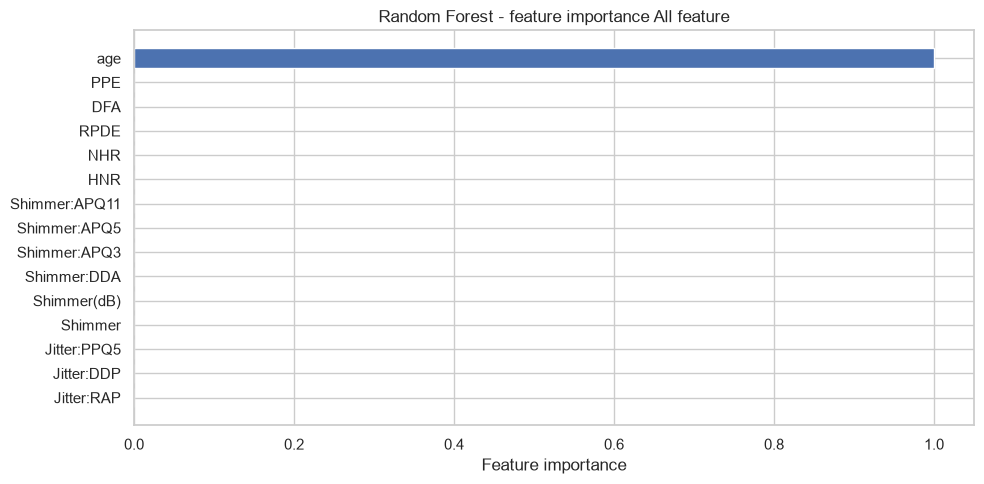

In [73]:
# Quick look at feature importance (all-features random forest model) 
# If age carries almost all the importance, that explains the identical folds.
rf_full_features = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 1000 ,n_jobs = -1,random_state = 42)
rf_full_features.fit(X_train[raw_col], y_train)

importances = rf_full_features.feature_importances_
feature_names = X_train[raw_col].columns

# sort descending for a readable plot
sorted_idx = np.argsort(importances)[::-1] # reversing vector

plt.figure(figsize = (10,5))
plt.barh(feature_names[sorted_idx][:15], importances[sorted_idx][:15])
plt.gca().invert_yaxis()
plt.xlabel('Feature importance')
plt.title('Random Forest - feature importance All feature')
plt.tight_layout()
plt.savefig('images/Random_forest_feature_importance_all_features.png', dpi = 300, bbox_inches = 'tight')
plt.show()

Everything so far asks whether voice predicts how severe a patient is compared with other patients. Telemonitoring is more often about whether voice tracks how a patient changes over time. Those are different questions, and the within-patient signal can exist even when the between-patient one doesn’t.So that, I've subtracted each patient’s own mean from the voice columns and from total_UPDRS, then correlate:

- the correlations, except for 'test_time', are near zero --> voice parameter don't correlate the disease severity

In [74]:
df = X_train.assign(y=y_train)
cols = voice_col + ['test_time']
within = df.groupby('subject#')[cols + ['y']].transform(lambda s: s - s.mean())
print(within.corr()['y'].sort_values())

Shimmer:APQ11   -0.072603
Shimmer:APQ5    -0.062237
RPDE            -0.055651
Shimmer(dB)     -0.054128
Shimmer         -0.051560
Shimmer:APQ3    -0.046319
Shimmer:DDA     -0.046316
DFA             -0.040526
NHR             -0.031277
PPE             -0.028901
Jitter(%)       -0.023748
Jitter:RAP      -0.021092
Jitter:DDP      -0.021090
Jitter:PPQ5     -0.016849
Jitter(Abs)     -0.011414
HNR              0.069649
test_time        0.464572
y                1.000000
Name: y, dtype: float64


In [75]:
# check if voice parameters add noise 
g = X_train['subject#']
for name, cols_ in [('time only', ['test_time']), ('time + voice', voice_col + ['test_time'])]:
    r2 = cross_val_score(LinearRegression(), within[cols_], within['y'],
                         groups = g, cv = GroupKFold(5), scoring = 'r2')
    print(name, r2.mean().round(3))

time only 0.178
time + voice 0.152


Consideration:

- Across patients, voice-only at its best equals the dummy. Only age helps, giving about 1 RMSE point.
- Within patients, voice correlations are <= 0.07, and adding voice to test_time lowers R² (0.178 -> 0.152).
- Time is the only real progression signal, and it needs a known baseline to be useful.

So, in this dataset, **the voice features carry no usable information about total UPDRS, either between or within patients**.

#### Test set evaluation

In [76]:
# fit dummy and demohraphic-based Random Forest

dummy = DummyRegressor(strategy = 'mean')
dummy.fit(X_train[['age', 'sex']], y_train)
dummy_pred = dummy.predict(X_test[['age','sex']])

dummy_rmse = root_mean_squared_error(y_test, dummy_pred)
dummy_r2 = r2_score(y_test, dummy_pred)
dummy_mae = mean_absolute_error(y_test, dummy_pred)

In [77]:
rf_dem = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 1000 ,n_jobs = -1,random_state = 42)
rf_dem.fit(X_train[['age', 'sex']], y_train)
rf_dem_pred= rf_dem.predict(X_test[['age','sex']])

rf_dem_rmse = root_mean_squared_error(y_test, rf_dem_pred)
rf_dem_r2 = r2_score(y_test, rf_dem_pred)
rf_dem_mae = mean_absolute_error(y_test, rf_dem_pred)

In [78]:
# compare result
comparison_dem = pd.DataFrame({'Model Metric':['dummy RMSE','dummy MAE','dummy R2','rf RMSE','rf MAE','rf R2'],
                              'value': [dummy_rmse,dummy_mae,dummy_r2,rf_dem_rmse,rf_dem_mae,rf_dem_r2]})

In [79]:
comparison_dem
# Its RMSE is 10.39 against 9.47, and its MAE is 9.33 against 7.99. In CV it won 4 of 5 folds by about 1 point. Here it loses by about 0.9

,Model Metric,value
0,dummy RMSE,9.465699
1,dummy MAE,7.989510
2,dummy R2,-0.081316
3,rf RMSE,10.393985
4,rf MAE,9.333425
5,rf R2,-0.303801


In [80]:
# built a per patience df
test_df = X_test[['subject#', 'age', 'sex']].assign(y=y_test, rf=rf_dem_pred, dummy=dummy_pred)
per_patient = test_df.groupby('subject#').agg(age=('age', 'first'), sex=('sex', 'first'),
                                              true_mean=('y', 'mean'), rf_pred=('rf', 'mean'),
                                              dummy_pred=('dummy', 'mean'), n=('y', 'size'))
per_patient['rf_err'] = (per_patient.rf_pred - per_patient.true_mean).abs()
per_patient['dummy_err'] = (per_patient.dummy_pred - per_patient.true_mean).abs()
print(per_patient.round(1))

          age  sex  true_mean  rf_pred  dummy_pred    n  rf_err  dummy_err
subject#                                                                  
5          75    0       41.9     35.1        29.6  156     6.8       12.3
9          68    0       25.1     35.1        29.6  152    10.0        4.5
14         58    1       18.0     24.7        29.6  136     6.7       11.5
20         67    0       16.9     35.1        29.6  134    18.1       12.6
26         49    0       31.3     24.7        29.6  130     6.6        1.8
27         57    1       15.4     24.7        29.6  129     9.3       14.1
30         49    0       36.9     24.7        29.6  126    12.2        7.3
31         75    0       29.6     35.1        29.6  130     5.5        0.0
40         85    1       26.0     35.1        29.6  142     9.1        3.6


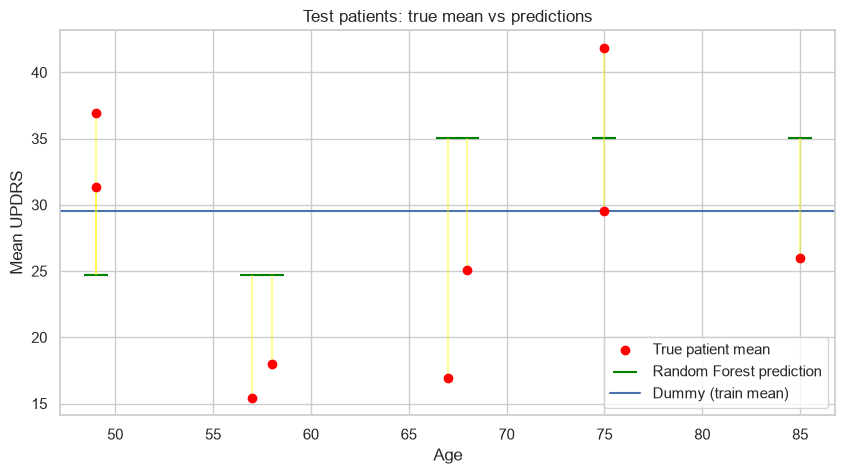

In [81]:
fig, ax = plt.subplots(figsize=(10, 5))
pp = per_patient.sort_values('age')
ax.scatter(pp['age'], pp['true_mean'], color = 'red', label = 'True patient mean', zorder = 3)
ax.scatter(pp['age'], pp['rf_pred'], marker = '_', s = 300, color = 'green', label = 'Random Forest prediction')
ax.axhline(pp['dummy_pred'].iloc[0], color = 'C0', label = 'Dummy (train mean)')
ax.vlines(pp['age'], pp['true_mean'], pp['rf_pred'], color = 'yellow', alpha = 0.4)  # RF error per patient
ax.set(xlabel = 'Age', ylabel = 'Mean UPDRS', title = 'Test patients: true mean vs predictions')
ax.legend(loc = 'lower right')
fig.savefig(images_dir / 'test_patients_true_vs_predicted.png', dpi=300, bbox_inches='tight')

Considerations:

- Random Forest model predicts only two values: 24.7 for the younger patients (ages 49 to 58) and 35.1 for the older ones (67 to 85). It is a single age split, somewhere between 58 and 67, with a gap of about 10 UPDRS points between the groups.
- The forest beats the dummy on 3 of 9 patients (5, 14, 27) and loses on 6.
- Mean absolute error per patient is 9.4 for the forest and 7.5 for the dummy.
- The biggest loss is patient 20 (age 67, true mean 16.9, predicted 35.1, error 18.1). Patient 5 is the only truly severe one (41.9), and the forest does help there.
- Within each age group, the true patient means span roughly 15 to 37 (younger) and 17 to 42 (older). Age explains little of that spread

# Conclusion:

- **Voice features**: no usable information about UPDRS across or within patients. This is supported by the sweep, the importances and the within-patient analysis.
- Age: a weak and unstable signal. It gave about +1 RMSE point in CV (4 of 5 folds) and about -0.9 on the test patients (3 of 9).
- The dominant source of variance is between-patient differences that none of these features capture.